## 1. Setup: GPU, Google Drive, libraries
**What it does:** detects Colab vs. your computer, mounts Google Drive (Colab only, a permission pop-up appears, click *Allow*), installs `ultralytics` (YOLOv8) and shows the GPU.
**Expected output:** `Running in Google Colab` (or `Running on a local computer`), then the GPU name, e.g. `Tesla T4`.

In [3]:
import sys, os

# Colab sets this module; on your own computer it is absent
IN_COLAB = "google.colab" in sys.modules
print("Running in Google Colab" if IN_COLAB else "Running on a local computer")

# Colab only: mount Google Drive so the notebook can read MyDrive/vision_drive
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')

# Install the YOLOv8 library (quiet mode)
%pip install -q ultralytics

# Show the GPU. Without a GPU, training falls back to the CPU and is very slow.
import torch
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available()
      else "none found (use Colab with a T4 GPU for training)")

Running in Google Colab
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: Tesla T4


## 2. Configuration
**What it does:** defines every path and setting in one place, plus the 10 detection classes. It chooses the Drive folder automatically (Colab: mounted Drive, own computer: the Google Drive for desktop folder).
**You must check (own computer only):** `DRIVE_DIR` must match what File Explorer shows (Google Drive > My Drive > vision_drive). The drive letter may be different from `G:`.
**You can change:** `N_TRAIN` / `N_VAL` (subset size), `EPOCHS`, `RUN_NAME`.
**Expected output:** none (just defines variables).

> `RUN_NAME` must be a **new** name each time you want a fresh training run, otherwise Ultralytics creates folders like `bdd_det_v22`.

In [4]:
import glob, json, random, shutil, zipfile
import cv2
import matplotlib.pyplot as plt

# ---------- Paths ----------
if IN_COLAB:
    DRIVE_DIR = "/content/drive/MyDrive/vision_drive"     # Google Drive mounted in Colab
    WORK_DIR  = "/content"                                # temporary working space
    WORKERS   = 2                                         # data-loading processes
else:
    # Google Drive for desktop folder on your computer (check the drive letter in File Explorer)
    DRIVE_DIR = "G:/My Drive/vision_drive"
    WORK_DIR  = os.path.join(os.path.expanduser("~"), "vision_drive_work").replace("\\", "/")
    WORKERS   = 0                                         # 0 avoids multiprocessing problems on Windows

os.makedirs(WORK_DIR, exist_ok=True)
LOCAL_DIR = f"{WORK_DIR}/local_zips"                 # fast local copy of the zips (Colab only)
OUT_DIR   = f"{WORK_DIR}/vision_drive_yolo"          # YOLO dataset is built here (temporary)

IMG_ZIP_NAME = "bdd100k_images_100k.zip"
LBL_ZIP_NAME = "bdd100k_labels.zip"
VIDEO_NAME   = "demo_clip.mp4"

# ---------- Dataset subset ----------
N_TRAIN = 5000      # number of training images to use
N_VAL   = 1000      # number of validation images to use
SEED    = 0         # makes the random subset reproducible

# ---------- Training ----------
RUN_NAME = "bdd_det_v2"
EPOCHS   = 30
IMG_SIZE = 640
BATCH    = 16

# ---------- Classes (the 10 BDD100K object detection classes) ----------
CLASSES = ["car", "bus", "truck", "train", "person", "rider",
           "bike", "motor", "traffic light", "traffic sign"]
CID = {c: i for i, c in enumerate(CLASSES)}   # class name -> class id
W, H = 1280, 720                              # BDD100K original image size

os.makedirs(LOCAL_DIR, exist_ok=True)
print("Drive folder:", DRIVE_DIR)
print("Work folder :", WORK_DIR)

Drive folder: /content/drive/MyDrive/vision_drive
Work folder : /content


##  downloading the 100K images from Kaggle straight into Colab

**What it does:** downloads the Kaggle dataset zip, and copies only the small `bdd100k_labels.zip` (0.2 GB) from your Drive. Then continue with Section 5.
**Note:** `KAGGLE_SLUG` is the dataset name on Kaggle. If the download fails with "404" or "403", open kaggle.com, search for `bdd100k` (a dataset with the 100K images), and put its `owner/name` in `KAGGLE_SLUG`.

In [10]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

LBL_ZIP = f"{DRIVE_DIR}/{LBL_ZIP_NAME}"
assert os.path.exists(LBL_ZIP), f"{LBL_ZIP_NAME} not found in {DRIVE_DIR}"
LOCAL_LBL_ZIP = f"{LOCAL_DIR}/{LBL_ZIP_NAME}"
shutil.copyfile(LBL_ZIP, LOCAL_LBL_ZIP)
print("Labels zip:", LOCAL_LBL_ZIP, f"({os.path.getsize(LOCAL_LBL_ZIP)/1e6:.0f} MB)")

Mounted at /content/drive
Labels zip: /content/local_zips/bdd100k_labels.zip (190 MB)


In [9]:
import getpass

KAGGLE_SLUG = "solesensei/solesensei_bdd100k"      # Kaggle dataset containing BDD100K images/100k/{train,val,test}

# ---- Kaggle credentials ----
%pip install -q -U kaggle
token = getpass.getpass("Paste your Kaggle API token (leave empty to upload kaggle.json instead): ")
if token.strip():
    os.environ["KAGGLE_API_TOKEN"] = token.strip()
else:
    from google.colab import files
    files.upload()                                           # choose kaggle.json
    os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
    shutil.move("kaggle.json", os.path.expanduser("~/.kaggle/kaggle.json"))
    os.chmod(os.path.expanduser("~/.kaggle/kaggle.json"), 0o600)

# ---- Download the images zip (several GB, takes a few minutes) ----
!kaggle datasets download -d {KAGGLE_SLUG} -p {LOCAL_DIR}

kaggle_zips = sorted(glob.glob(f"{LOCAL_DIR}/*.zip"), key=os.path.getsize, reverse=True)
assert kaggle_zips, "Kaggle download failed: check the token and KAGGLE_SLUG (see the note above)."
LOCAL_IMG_ZIP = kaggle_zips[0]
print("Images zip:", LOCAL_IMG_ZIP, f"({os.path.getsize(LOCAL_IMG_ZIP)/1e9:.2f} GB)")

# ---- Labels: small zip copied from your Drive ----
LBL_ZIP = f"{DRIVE_DIR}/{LBL_ZIP_NAME}"
assert os.path.exists(LBL_ZIP), f"{LBL_ZIP_NAME} not found in {DRIVE_DIR}"
LOCAL_LBL_ZIP = f"{LOCAL_DIR}/{LBL_ZIP_NAME}"
shutil.copyfile(LBL_ZIP, LOCAL_LBL_ZIP)
print("Labels zip:", LOCAL_LBL_ZIP)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 5.5 MB/s eta 0:00:00
Paste your Kaggle API token (leave empty to upload kaggle.json instead): ··········
Dataset URL: https://www.kaggle.com/datasets/solesensei/solesensei_bdd100k
License(s): other
100% 7.61G/7.61G [01:23<00:00, 97.2MB/s]

Images zip: /content/local_zips/solesensei_bdd100k.zip (8.17 GB)
Labels zip: /content/local_zips/bdd100k_labels.zip


## 5. Inspect the zip structure
**What it does:** opens both zips *without extracting them* and counts files per split.
**Expected output (approximately):**
- images: about 70,000 in `train`, 10,000 in `val`, 20,000 in `test`
- labels: about 70,000 in `train`, 10,000 in `val`
**Note:** the `test` images have no labels, so they are never used.

In [11]:
img_zf = zipfile.ZipFile(LOCAL_IMG_ZIP)
lbl_zf = zipfile.ZipFile(LOCAL_LBL_ZIP)
img_names = img_zf.namelist()
lbl_names = lbl_zf.namelist()

# Some zips also contain other image sets: keep only the 100K images folder if it exists
if any("/100k/" in "/" + n for n in img_names):
    img_names = [n for n in img_names if "/100k/" in "/" + n]

def in_split(name, split):
    """True if the file lives in a folder called <split>, e.g. 100k/train/xxx.jpg"""
    return f"/{split}/" in "/" + name

def stem_of(name):
    """File name without folder and extension: 100k/train/abc-123.jpg -> abc-123"""
    return os.path.splitext(os.path.basename(name))[0]

for split in ["train", "val", "test"]:
    n_img = sum(1 for n in img_names if n.lower().endswith(".jpg") and in_split(n, split))
    n_lbl = sum(1 for n in lbl_names if n.lower().endswith(".json") and in_split(n, split))
    print(f"{split:5s}  images: {n_img:6d}   labels: {n_lbl:6d}")

print("\nExample image path:", next(n for n in img_names if n.lower().endswith(".jpg")))
print("Example label path:", next(n for n in lbl_names if n.lower().endswith(".json")))

train  images:  70000   labels:  70000
val    images:  10000   labels:  10000
test   images:  20000   labels:  20000

Example image path: bdd100k/bdd100k/images/100k/test/cb2fe290-8786cd14.jpg
Example label path: 100k/train/6866acb3-cf17e759.json


## 6. Build the YOLO dataset (subset)
**What it does:**
1. Picks `N_TRAIN` random training and `N_VAL` random validation images.
2. Finds the label JSON with the **same file name** as each image.
3. Converts each box to YOLO format: `class x_center y_center width height` (all normalised 0 to 1).
4. Writes images, label `.txt` files and `data.yaml` to `OUT_DIR`.

**Expected output:** `[train] converted: 5000 images, ... boxes` and the same for val, then the contents of `data.yaml`.
The previous dataset in `OUT_DIR` is deleted first, so old data never mixes with new data.

In [12]:
def build_split(split, n):
    """Create <n> images + YOLO label files for one split (train or val)."""
    imgs = [x for x in img_names if x.lower().endswith(".jpg") and in_split(x, split)]
    lbls = {stem_of(x): x for x in lbl_names if x.lower().endswith(".json") and in_split(x, split)}
    assert imgs and lbls, f"No images or labels found for split '{split}'"

    img_out = f"{OUT_DIR}/images/{split}"
    lbl_out = f"{OUT_DIR}/labels/{split}"
    os.makedirs(img_out, exist_ok=True)
    os.makedirs(lbl_out, exist_ok=True)

    random.seed(SEED)
    random.shuffle(imgs)

    done, boxes = 0, 0
    for name in imgs:
        stem = stem_of(name)
        if stem not in lbls:
            continue                                    # image without a label file: skip

        data = json.loads(lbl_zf.read(lbls[stem]))
        objs = data["frames"][0].get("objects", []) if data.get("frames") else []

        lines = []
        for obj in objs:
            # keep only the 10 detection classes that have a bounding box
            if "box2d" not in obj or obj["category"] not in CID:
                continue
            b = obj["box2d"]
            x1, y1 = max(0, b["x1"]), max(0, b["y1"])
            x2, y2 = min(W, b["x2"]), min(H, b["y2"])
            bw, bh = x2 - x1, y2 - y1
            if bw <= 1 or bh <= 1:
                continue                                # degenerate box
            lines.append(f"{CID[obj['category']]} {(x1+x2)/2/W:.6f} {(y1+y2)/2/H:.6f} {bw/W:.6f} {bh/H:.6f}")

        with open(f"{lbl_out}/{stem}.txt", "w") as f:
            f.write("\n".join(lines))
        with open(f"{img_out}/{stem}.jpg", "wb") as f:
            f.write(img_zf.read(name))

        done += 1
        boxes += len(lines)
        if done >= n:
            break
    print(f"[{split}] converted: {done} images, {boxes} boxes")

# Start from a clean folder
shutil.rmtree(OUT_DIR, ignore_errors=True)

build_split("train", N_TRAIN)
build_split("val", N_VAL)

# data.yaml tells YOLO where the data is and what the class names are
with open(f"{OUT_DIR}/data.yaml", "w") as f:
    f.write(f"path: {OUT_DIR}\ntrain: images/train\nval: images/val\nnames:\n")
    for i, c in enumerate(CLASSES):
        f.write(f"  {i}: {c}\n")
print("\n" + open(f"{OUT_DIR}/data.yaml").read())

[train] converted: 5000 images, 91219 boxes
[val] converted: 1000 images, 19038 boxes

path: /content/vision_drive_yolo
train: images/train
val: images/val
names:
  0: car
  1: bus
  2: truck
  3: train
  4: person
  5: rider
  6: bike
  7: motor
  8: traffic light
  9: traffic sign



## 7. Visual check: are the labels correct?
**What it does:** draws the labels on 6 random training images.
**What to look for:** every box must sit tightly on a car, person, traffic light or sign. Large boxes on empty road or sky mean the labels do not match the images, and you should **not** train. Re-run the cell to see other random images.

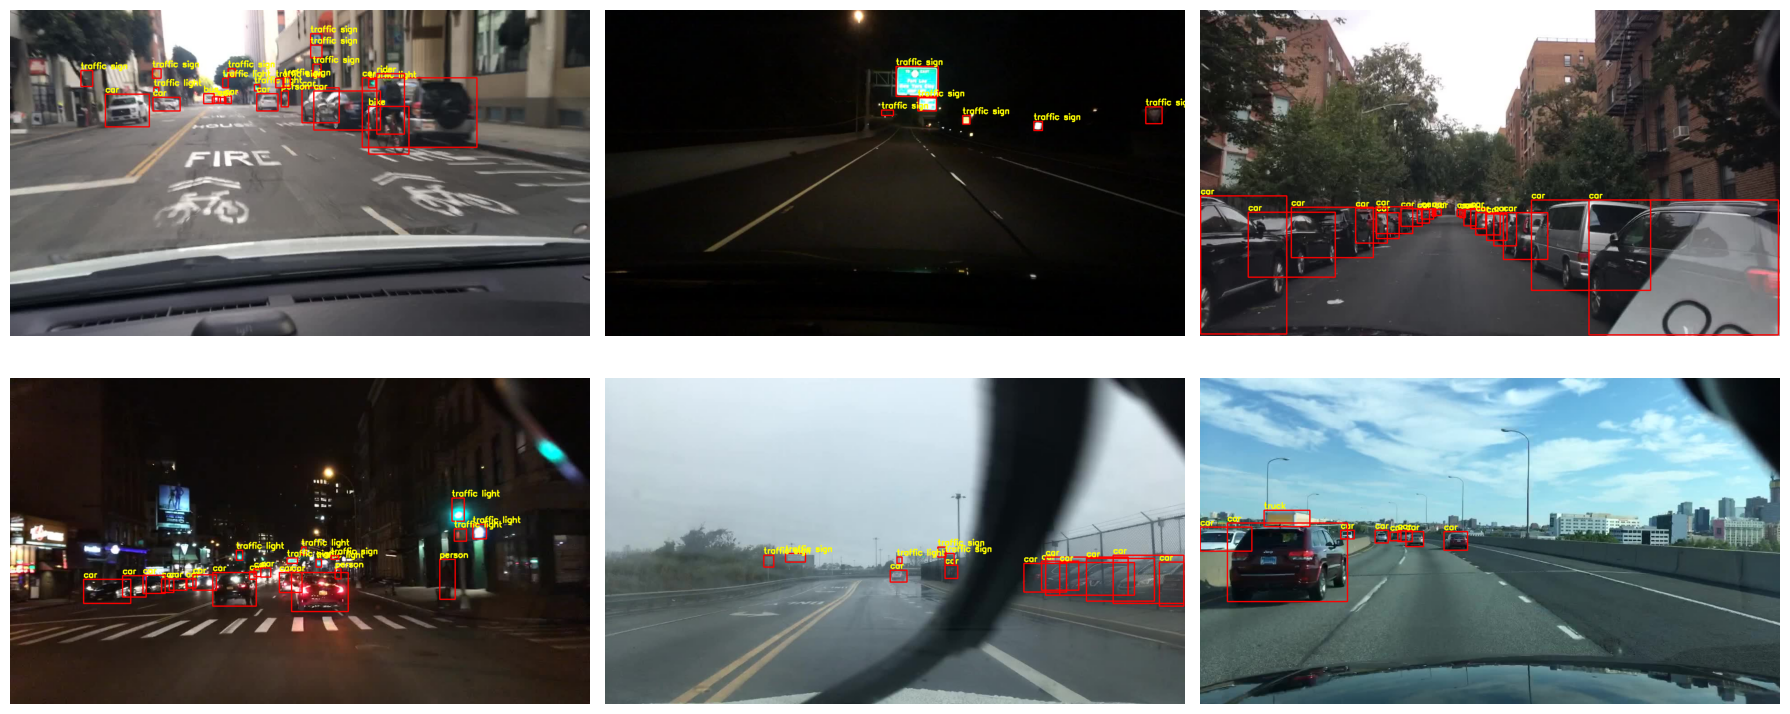

In [9]:
def show_samples(split="train", k=6):
    paths = random.sample(glob.glob(f"{OUT_DIR}/images/{split}/*.jpg"), k)
    fig, axs = plt.subplots(2, 3, figsize=(18, 8))
    for ax, p in zip(axs.ravel(), paths):
        img = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
        ih, iw = img.shape[:2]
        lbl = p.replace("/images/", "/labels/").replace(".jpg", ".txt")
        for line in open(lbl).read().splitlines():
            c, cx, cy, bw, bh = line.split()
            cx, cy, bw, bh = float(cx) * iw, float(cy) * ih, float(bw) * iw, float(bh) * ih
            x1, y1, x2, y2 = int(cx - bw / 2), int(cy - bh / 2), int(cx + bw / 2), int(cy + bh / 2)
            cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 0), 2)
            cv2.putText(img, CLASSES[int(c)], (x1, max(12, y1 - 4)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 0), 2)
        ax.imshow(img)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

show_samples("train")

## 8. Automatic label alignment check
**What it does:** runs a pretrained COCO YOLOv8 model on 80 validation images and measures how many of its *car* detections overlap one of your *car* labels (IoU > 0.5). A pretrained model knows nothing about your labels, so a high overlap proves the labels are aligned with the images.

**How to read the result:**
- **above 50%**: labels are correct, go ahead and train
- **below 10%**: labels do not match the images, do not train

In [10]:
import torch
from ultralytics import YOLO
from ultralytics.utils.metrics import box_iou

coco = YOLO("yolov8n.pt")        # pretrained on COCO, class 2 = car
val_imgs = sorted(glob.glob(f"{OUT_DIR}/images/val/*.jpg"))[:80]

hit, total = 0, 0
for p in val_imgs:
    pred = coco.predict(p, classes=[2], conf=0.4, verbose=False)[0]
    det = pred.boxes.xyxyn                       # predicted boxes, normalised xyxy
    if len(det) == 0:
        continue
    gt = []
    for line in open(p.replace("/images/", "/labels/").replace(".jpg", ".txt")).read().splitlines():
        c, cx, cy, bw, bh = line.split()
        if int(c) == CID["car"]:
            cx, cy, bw, bh = map(float, (cx, cy, bw, bh))
            gt.append([cx - bw / 2, cy - bh / 2, cx + bw / 2, cy + bh / 2])
    total += len(det)
    if gt:
        hit += (box_iou(det.cpu(), torch.tensor(gt)).max(1).values > 0.5).sum().item()

print(f"COCO car detections matching your labels (IoU > 0.5): {hit}/{total} = {hit / max(total, 1):.1%}")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
COCO car detections matching your labels (IoU > 0.5): 290/317 = 91.5%


## 9. Class distribution
**What it does:** counts boxes per class in the training set.
**Expected output:** `car` has the most boxes, `train` and `motor` very few. Rare classes will have a low accuracy, which is normal for BDD100K.

In [11]:
from collections import Counter

counts = Counter()
for f in glob.glob(f"{OUT_DIR}/labels/train/*.txt"):
    for line in open(f).read().splitlines():
        if line.strip():
            counts[CLASSES[int(line.split()[0])]] += 1

for c in CLASSES:
    print(f"{c:15s} {counts[c]:7d}")

car               50338
bus                 883
truck              2152
train                10
person             6566
rider               366
bike                595
motor               242
traffic light     13155
traffic sign      16912


## 10. Train YOLOv8
**What it does:** fine-tunes the pretrained `yolov8n` model on your subset. Results and weights are saved to `vision_drive/runs/<RUN_NAME>` on Drive, so they survive a disconnect.
**Expected output:** one line per epoch with the losses and mAP. About 1 to 2 minutes per epoch on a T4 GPU with 5000 images, so roughly 30 to 60 minutes for 30 epochs. (On a CPU it is many times slower.)
**Healthy signs:** `box_loss` and `cls_loss` go down, `mAP50` goes up after the first few epochs.

In [12]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")          # small, fast starting model (pretrained on COCO)
model.train(
    data=f"{OUT_DIR}/data.yaml",    # dataset description created in Section 6
    epochs=EPOCHS,
    patience=10,                    # stop early only if there is no improvement for 10epochs
    imgsz=IMG_SIZE,
    batch=BATCH,
    workers=WORKERS,                # data-loading processes (0 on Windows)
    project=f"{DRIVE_DIR}/runs",    # results are saved in Google Drive
    name=RUN_NAME,
)

Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/vision_drive_yolo/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=bdd_det_v2, nbs=64, nms=None, opset=None, optimize=Fa

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7df811dc83d0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.0

## 11. Evaluate and show results
**What it does:** validates the best weights (`best.pt`) and prints overall and per-class metrics, then shows the training curves and the confusion matrix.
**Metrics:** `mAP50` = detection accuracy at IoU 0.5 (higher is better). `mAP50-95` is stricter.

Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,134,894 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1719.6±761.4 MB/s, size: 58.6 KB)
val: Scanning /content/vision_drive_yolo/labels/val.cache... 1000 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1000/1000 322.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 63/63 5.4it/s 11.7s
                   all       1000      19038      0.604      0.356      0.376      0.198
                   car        986      10524      0.711      0.628      0.682      0.405
                   bus        148        195      0.506       0.39      0.406      0.306
                 truck        290        451       0.52      0.461      0.451      0.307
                 train          2          3          1          0          0          0
                person        332  

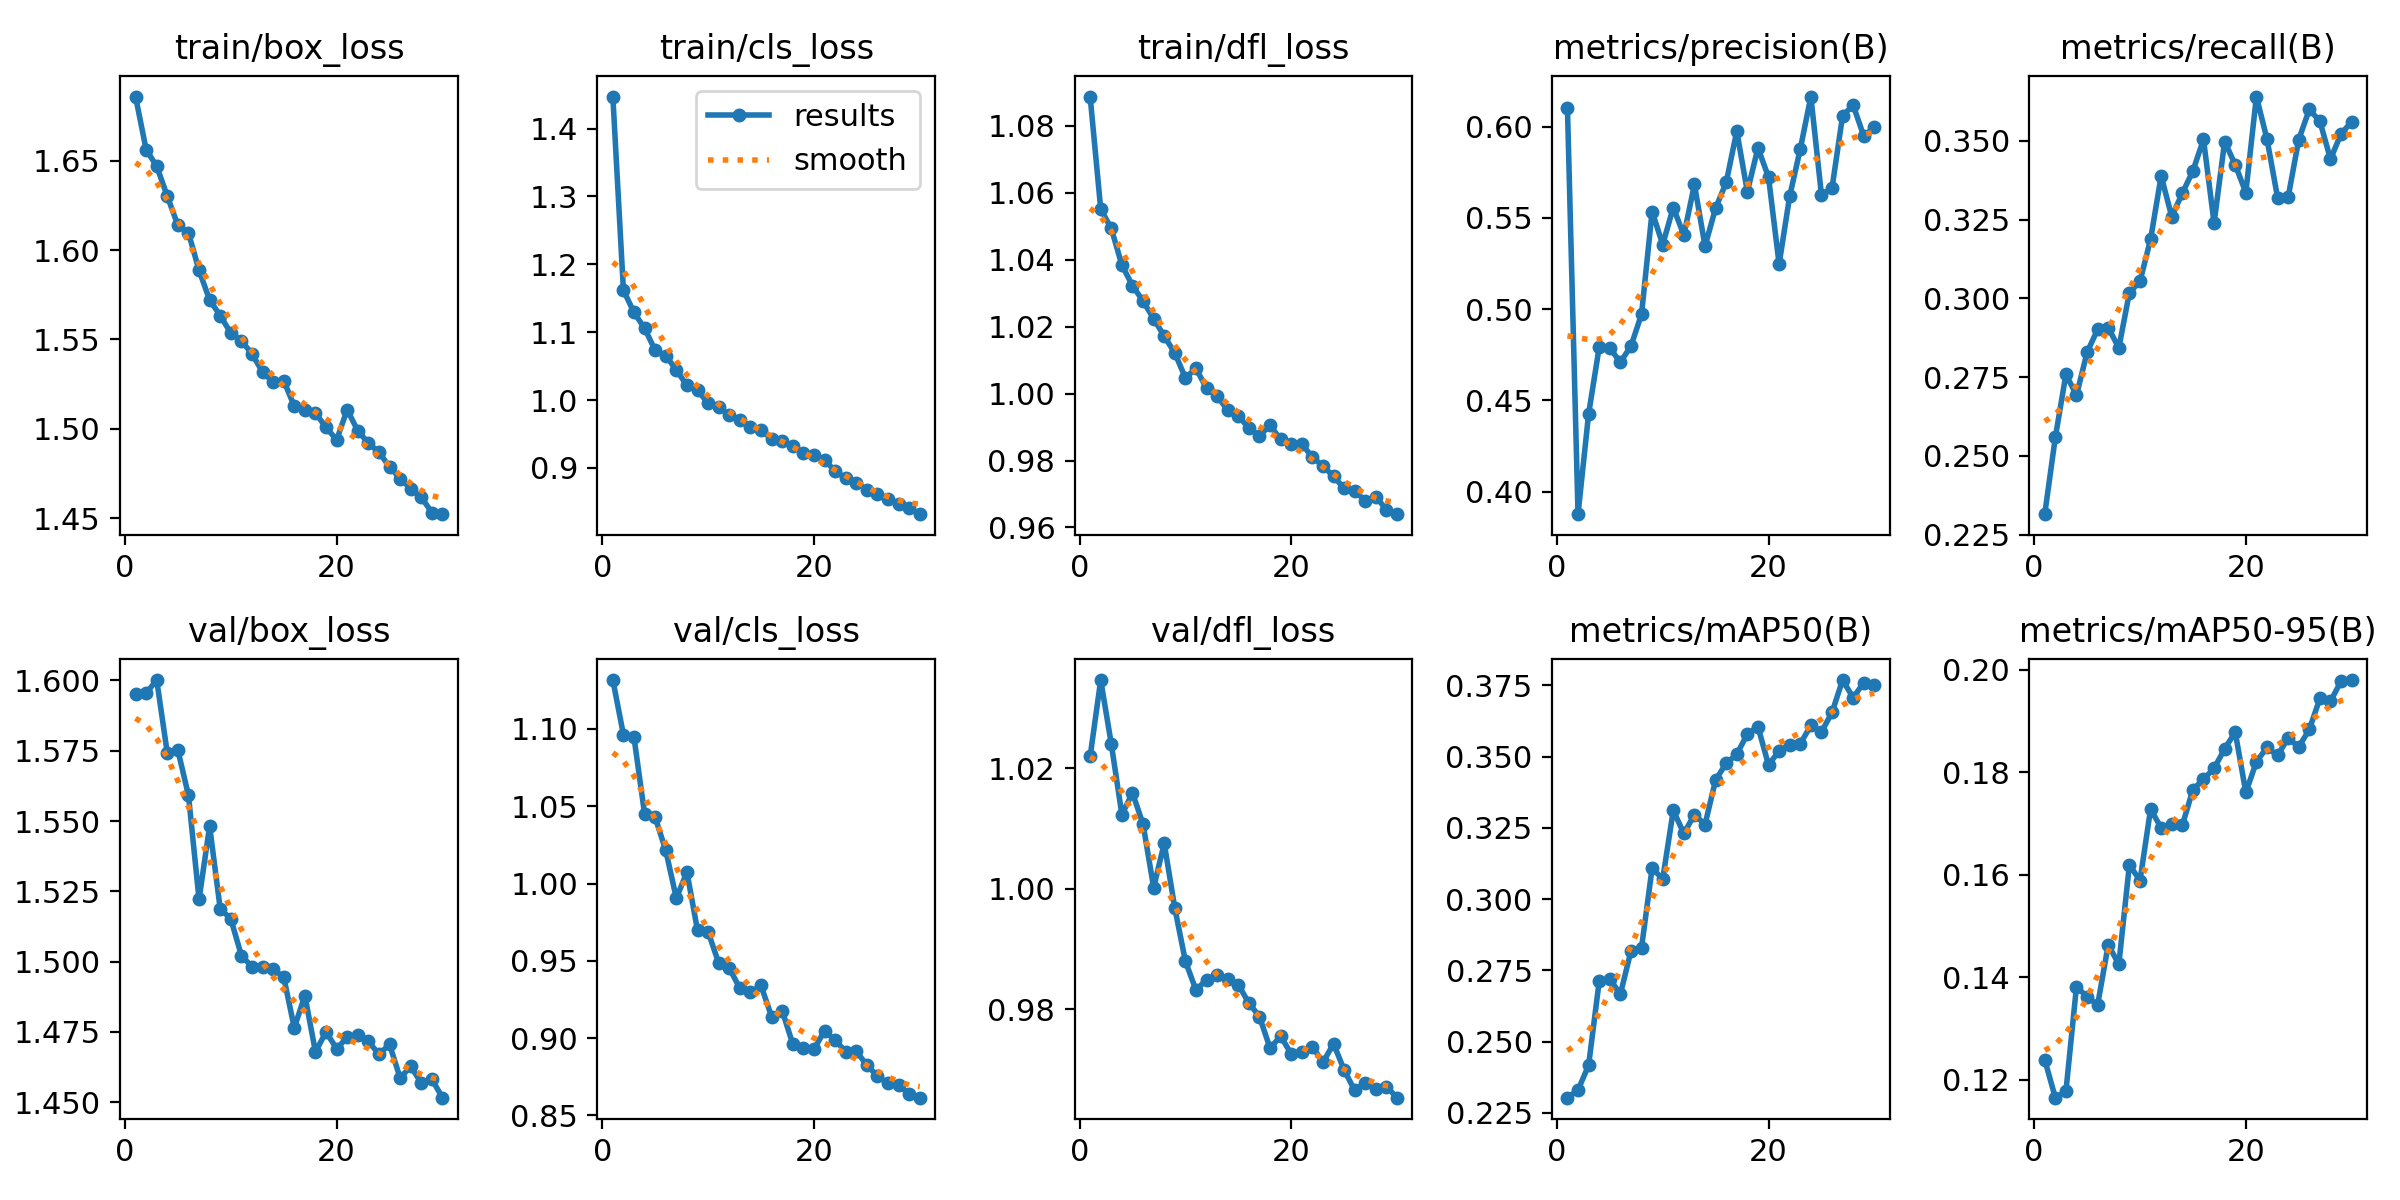

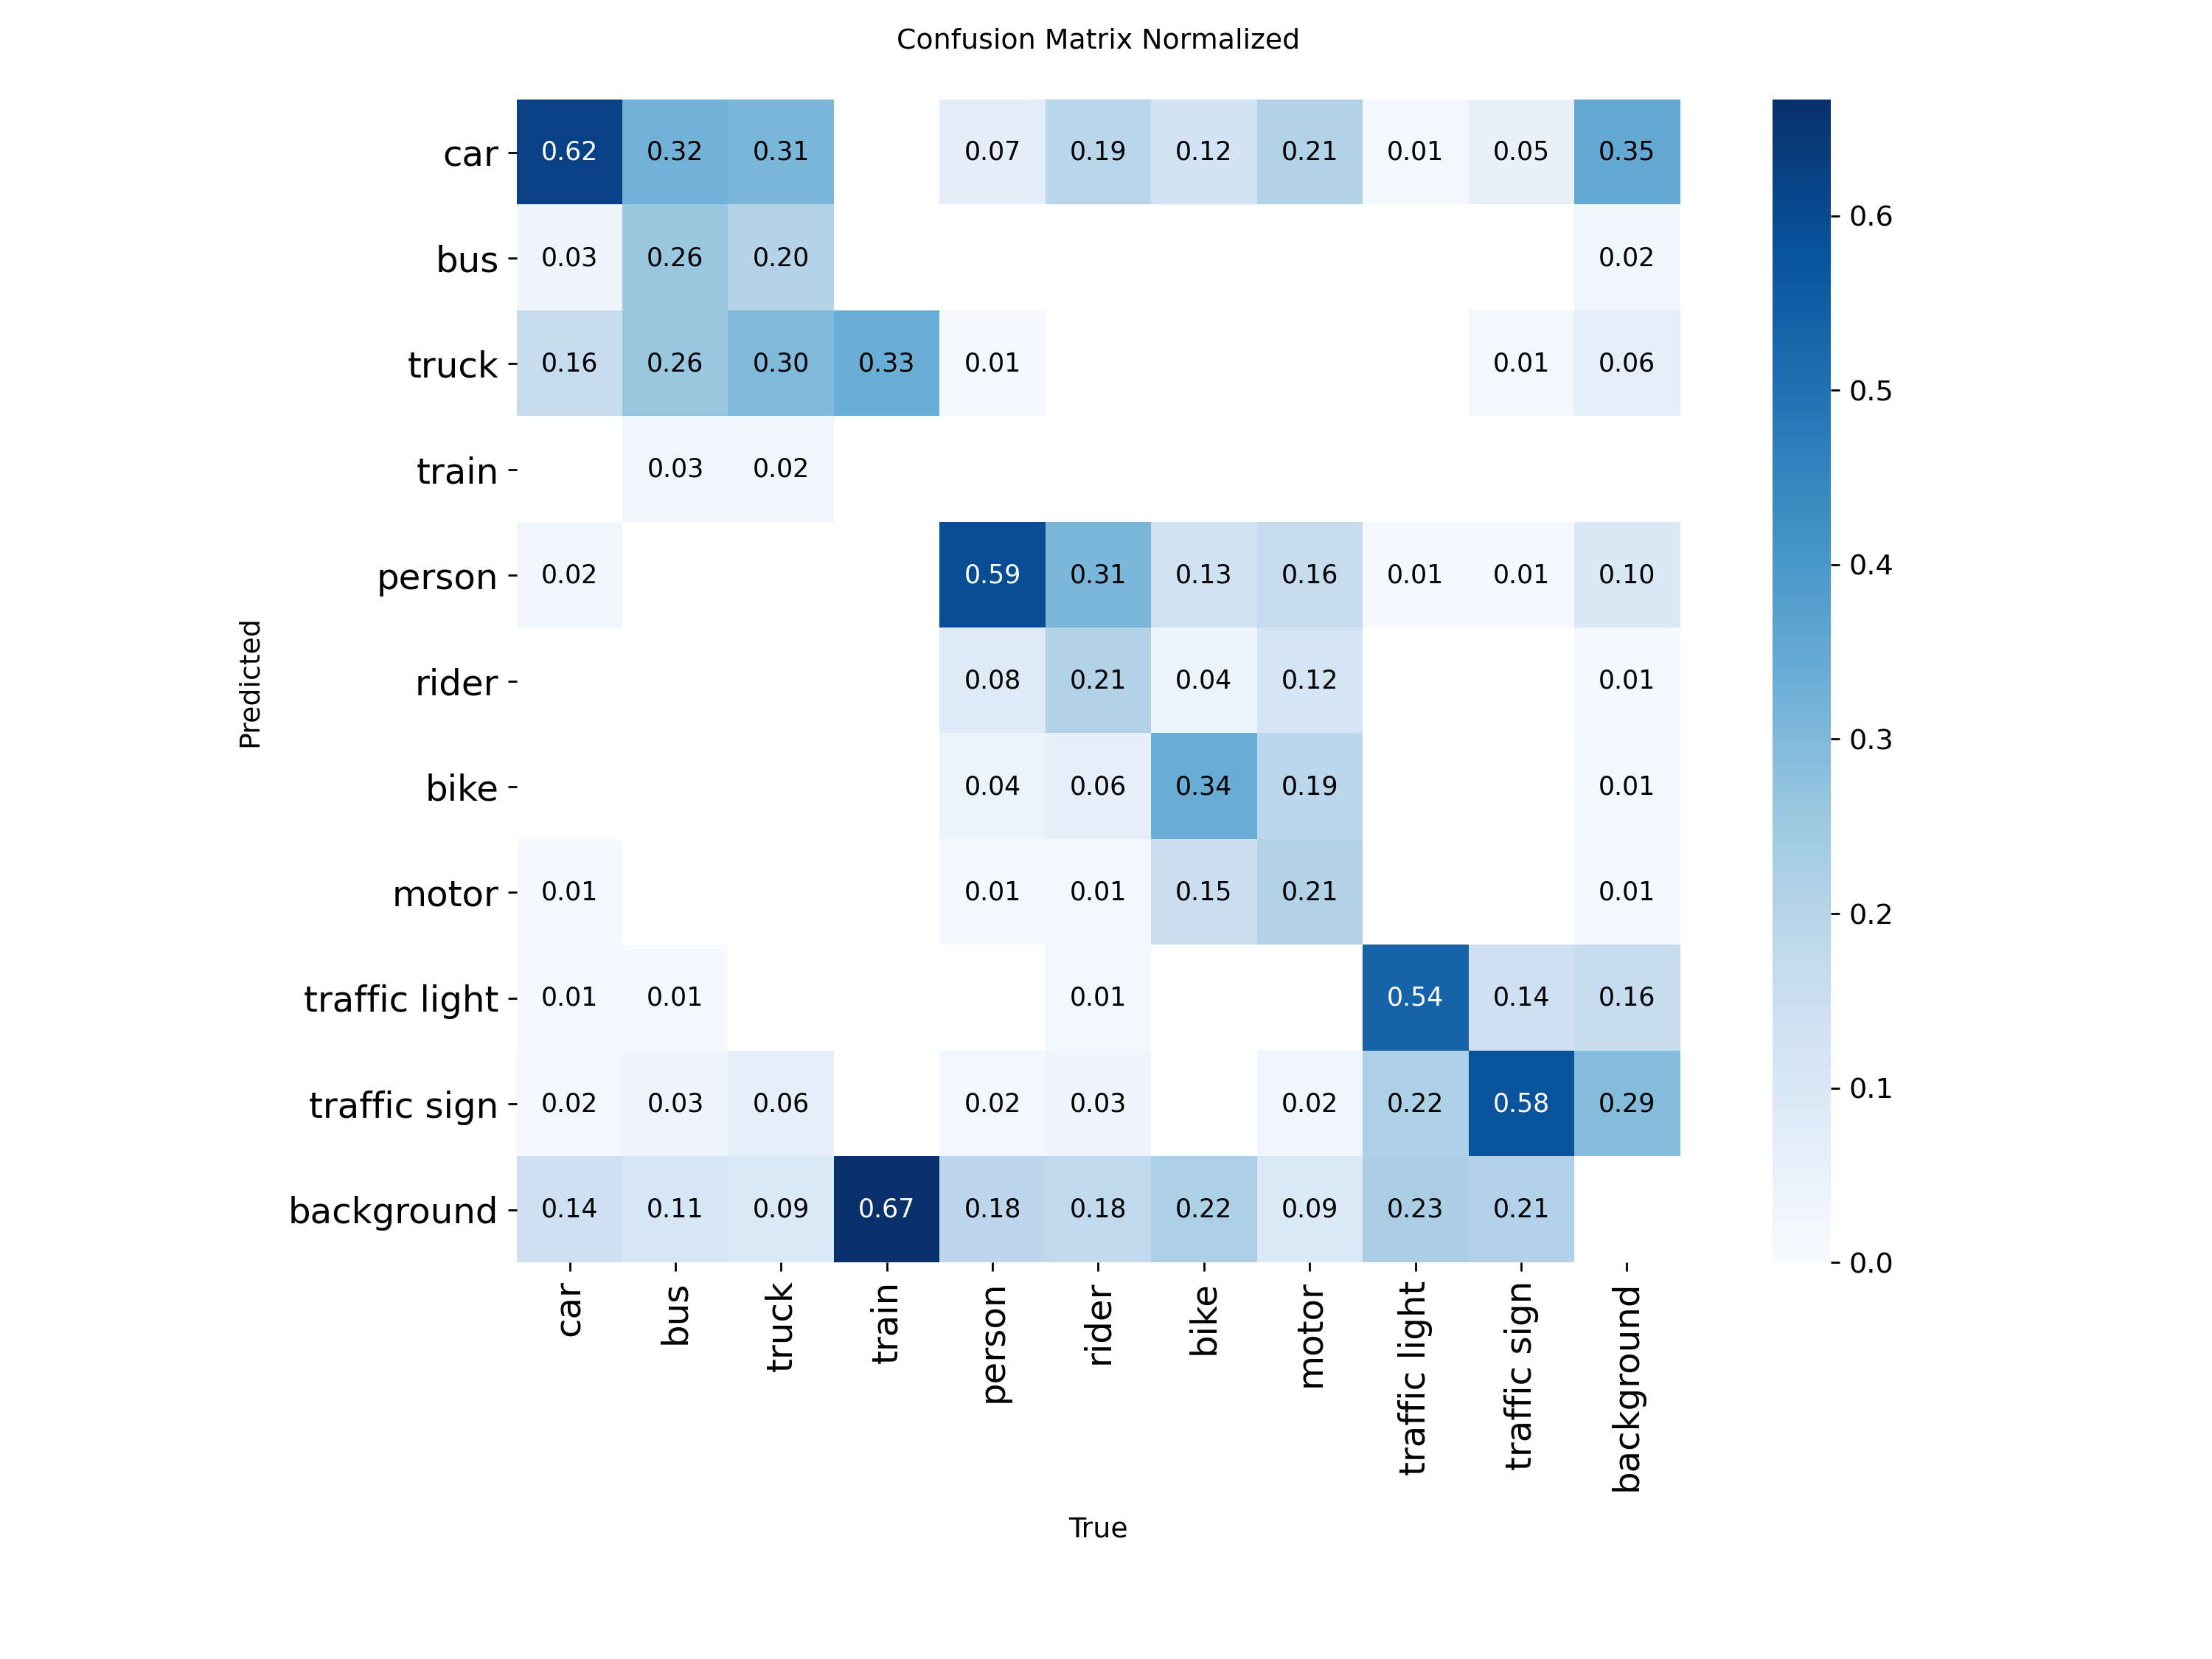

In [13]:
from IPython.display import Image, display

run_dir = f"{DRIVE_DIR}/runs/{RUN_NAME}"
best = YOLO(f"{run_dir}/weights/best.pt")

metrics = best.val(data=f"{OUT_DIR}/data.yaml", verbose=True)
print(f"\nOverall mAP50: {metrics.box.map50:.3f}   mAP50-95: {metrics.box.map:.3f}")

# Training curves and confusion matrix saved by Ultralytics
for fname in ["results.png", "confusion_matrix_normalized.png"]:
    path = f"{run_dir}/{fname}"
    if os.path.exists(path):
        display(Image(path, width=900))

## 12. Run the model on a video (demo)
**What it does:** runs the trained model on `demo_clip.mp4` and saves the annotated video to `vision_drive/runs/demo_out/`. The `.avi` that Ultralytics writes is also converted to `.mp4` (if `ffmpeg` is installed; Colab has it).
**Needs:** `demo_clip.mp4` inside the Drive folder (a 10 to 30 second dashcam clip works well). If the file is missing, this cell only prints a message.

In [5]:
from ultralytics import YOLO
import subprocess, glob, shutil, os

video_path = f"{DRIVE_DIR}/{VIDEO_NAME}"
assert os.path.exists(video_path), f"{VIDEO_NAME} not found in {DRIVE_DIR}"

model = YOLO(f"{DRIVE_DIR}/runs/{RUN_NAME}/weights/best.pt")

# Write the output to Colab's local disk first (faster and safer than writing to Drive directly)
local_out = "/content/demo_runs"
shutil.rmtree(local_out, ignore_errors=True)

# stream=True processes one frame at a time, so RAM does not fill up
for _ in model.predict(source=video_path, stream=True, save=True, conf=0.3,
                       project=local_out, name="demo_out", exist_ok=True, verbose=False):
    pass

# Convert to MP4 and copy the result to Google Drive
final_dir = f"{DRIVE_DIR}/runs/demo_out"
os.makedirs(final_dir, exist_ok=True)
for video in glob.glob(f"{local_out}/demo_out/*.avi") + glob.glob(f"{local_out}/demo_out/*.mp4"):
    if video.endswith(".avi") and shutil.which("ffmpeg"):
        mp4 = video.replace(".avi", "_out.mp4")
        subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", video,
                        "-vcodec", "libx264", "-pix_fmt", "yuv420p", mp4], check=True)
        video = mp4
    shutil.copy(video, final_dir)
    print("Saved:", f"{final_dir}/{os.path.basename(video)}")

Results saved to /content/demo_runs/demo_out
Saved: /content/drive/MyDrive/vision_drive/runs/demo_out/demo_clip_out.mp4


## 13. Optional: save / restore the prepared dataset
**Why:** if Colab disconnects, `OUT_DIR` is wiped. Saving it to Drive lets you skip Sections 4 to 6 next time.

- **Save:** run once after Section 6. Creates `vision_drive/dataset_cache.zip`.
- **Restore:** in a new session run Sections 1 and 2, then this restore cell, then continue from Section 7.

In [13]:
# SAVE the prepared dataset to Drive (run once after Section 6)
cache_path = f"{DRIVE_DIR}/dataset_cache.zip"
shutil.make_archive(cache_path[:-4], "zip", OUT_DIR)
print("Saved:", cache_path, f"({os.path.getsize(cache_path)/1e9:.2f} GB)")

Saved: /content/drive/MyDrive/vision_drive/dataset_cache.zip (0.35 GB)


In [14]:
# RESTORE the prepared dataset from Drive (new session: run Sections 1-2 first, skip Sections 3-6)
cache_path = f"{DRIVE_DIR}/dataset_cache.zip"
shutil.rmtree(OUT_DIR, ignore_errors=True)
shutil.unpack_archive(cache_path, OUT_DIR)
print("Restored:",
      len(glob.glob(f"{OUT_DIR}/images/train/*.jpg")), "train images,",
      len(glob.glob(f"{OUT_DIR}/images/val/*.jpg")), "val images")
print(open(f"{OUT_DIR}/data.yaml").read())

Restored: 5000 train images, 1000 val images
path: /content/vision_drive_yolo
train: images/train
val: images/val
names:
  0: car
  1: bus
  2: truck
  3: train
  4: person
  5: rider
  6: bike
  7: motor
  8: traffic light
  9: traffic sign

